In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("ride_hailing_dataset.csv")
df.head()

,trip_id,city,service_type,fare,distance_km,payment_method,trip_rating,gender
0,T001,Lahore,Uber,984.44,17.2,Cash,3,Female
1,T002,Islamabad,Uber,539.46,2.5,Wallet,5,Female
2,T003,Karachi,Careem,401.60,8.0,Card,4,Male
3,T004,Lahore,Uber,932.56,16.2,Wallet,3,Female
4,T005,Lahore,Rickshaw,148.61,19.2,Card,5,Female


In [3]:
print(df.shape)
print(df.dtypes)
print(df.isna().sum())

(100, 8)
trip_id            object
city               object
service_type       object
fare              float64
distance_km       float64
payment_method     object
trip_rating         int64
gender             object
dtype: object
trip_id           0
city              0
service_type      0
fare              0
distance_km       0
payment_method    0
trip_rating       0
gender            0
dtype: int64


In [4]:
avg_fare = df.groupby("service_type")["fare"].mean().round(2)
avg_fare

service_type
Careem      544.98
InDrive     573.51
Rickshaw    486.64
Uber        486.13
Name: fare, dtype: float64

In [5]:
city_counts = df["city"].value_counts()
city_counts

city
Islamabad     29
Lahore        26
Karachi       23
Rawalpindi    22
Name: count, dtype: int64

In [6]:
print("City with the most trips:", city_counts.idxmax())

City with the most trips: Islamabad


In [7]:
avg_distance = df["distance_km"].mean()
print("Average distance:", round(avg_distance, 2), "km")

Average distance: 9.61 km


In [8]:
df.groupby("gender")["trip_rating"].agg(["mean", "median", "count"]).round(2)

,mean,median,count
gender,,,
Female,2.82,3.0,51
Male,3.33,4.0,49


In [9]:
pd.crosstab(df["gender"], df["trip_rating"])

trip_rating,1,2,3,4,5
gender,,,,,
Female,14,9,8,12,8
Male,7,10,7,10,15


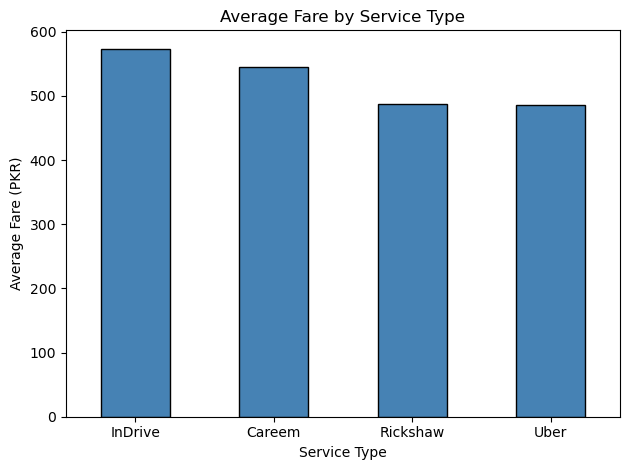

In [10]:
avg_fare_sorted = avg_fare.sort_values(ascending=False)

avg_fare_sorted.plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("Average Fare by Service Type")
plt.xlabel("Service Type")
plt.ylabel("Average Fare (PKR)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()